# 05 · Placar das três configurações

| Config | O que é |
|---|---|
| **A** | Mesmo modelo, **sem contexto** (linha de base de alucinação) |
| **B** | **RAG simples**: busca E5 top-3 + limiar + prompt com citação obrigatória |
| **C** | **RAG + LoRA**: igual a B, com o adaptador treinado no notebook 04 |

Conjunto de teste: 50 perguntas (40 respondíveis + 10 "não consta"), gabarito em `avaliacao/perguntas_teste.jsonl`.
Definições das métricas em `src/zela/avaliacao.py` e no relatório.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src")); sys.path.insert(0, os.path.abspath("../scripts"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [2]:
%run ../scripts/avaliar.py --configs A B C

W1112 16:25:00.377000 19072 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

busca=e5 limiar=0.8511 modelo=Qwen/Qwen2.5-1.5B-Instruct


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

config A:   0%|          | 0/50 [00:00<?, ?it/s]

... (139 outputs left out)

config C:  84%|████████▍ | 42/50 [05:08<00:51,  6.42s/it]

config C:  96%|█████████▌| 48/50 [05:16<00:05,  2.69s/it]

config C: 100%|██████████| 50/50 [05:16<00:00,  6.33s/it]

| Config | acuracia_respondiveis | recusa_correta_nao_consta | recusa_indevida | taxa_alucinacao | json_valido | citacao_correta | citacao_fantasma | latencia_media_s | n_perguntas |
|---|---|---|---|---|---|---|---|---|---|
| A — Modelo sem contexto | 10.0% | 0.0% | 0.0% | 64.0% | 72.0% | 5.0% | 32.0% | 3.15 | 50 |
| B — RAG simples (busca + limiar + citação) | 20.0% | 70.0% | 0.0% | 8.0% | 38.0% | 25.0% | 0.0% | 3.39 | 50 |
| C — RAG + LoRA (modelo especializado) | 87.5% | 80.0% | 0.0% | 14.0% | 100.0% | 92.5% | 0.0% | 6.33 | 50 |

88 falhas listadas em avaliacao/resultados/candidatos_erro.csv


In [3]:
placar = pd.read_csv("../avaliacao/placar.csv", index_col=0)
display(Markdown(open("../avaliacao/placar.md", encoding="utf-8").read()))

# Placar — 50 perguntas (40 respondíveis + 10 'não consta')

Modelo: `Qwen/Qwen2.5-1.5B-Instruct` · Busca: `e5` · top-k=3 · limiar=0.8511

| Config | acuracia_respondiveis | recusa_correta_nao_consta | recusa_indevida | taxa_alucinacao | json_valido | citacao_correta | citacao_fantasma | latencia_media_s | n_perguntas |
|---|---|---|---|---|---|---|---|---|---|
| A — Modelo sem contexto | 10.0% | 0.0% | 0.0% | 64.0% | 72.0% | 5.0% | 32.0% | 3.15 | 50 |
| B — RAG simples (busca + limiar + citação) | 20.0% | 70.0% | 0.0% | 8.0% | 38.0% | 25.0% | 0.0% | 3.39 | 50 |
| C — RAG + LoRA (modelo especializado) | 87.5% | 80.0% | 0.0% | 14.0% | 100.0% | 92.5% | 0.0% | 6.33 | 50 |


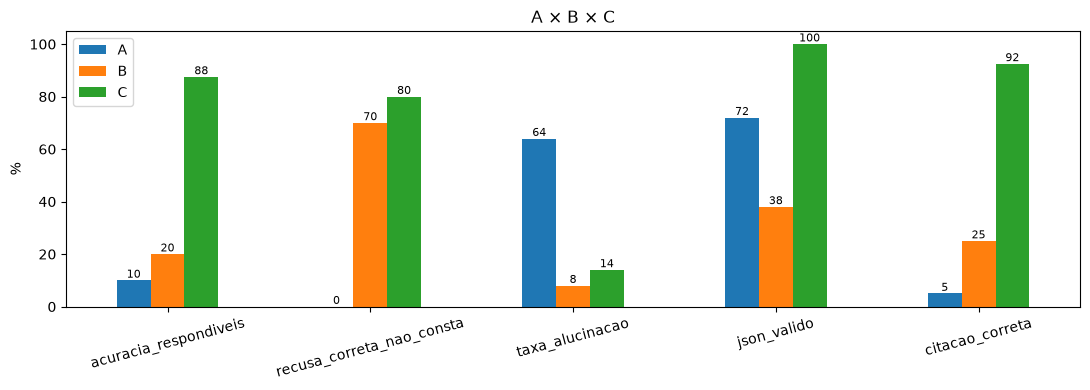

In [4]:
metricas = ["acuracia_respondiveis", "recusa_correta_nao_consta", "taxa_alucinacao", "json_valido", "citacao_correta"]
ax = (placar[metricas] * 100).T.plot.bar(figsize=(11, 4), rot=15)
ax.set_ylabel("%"); ax.set_title("A × B × C"); ax.set_ylim(0, 105)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
plt.tight_layout(); plt.savefig("../avaliacao/resultados/placar.png", dpi=120); plt.show()

## Acerto por categoria

In [5]:
corr = pd.read_csv("../avaliacao/resultados/correcao.csv")
corr[~corr.deve_recusar].pivot_table(index="categoria", columns="config", values="acerto", aggfunc="mean").round(2)

config,A,B,C
categoria,,,
arvore,0.00,0.00,0.67
buraco_via,0.12,0.12,0.88
calcada,0.09,0.18,0.82
canais,0.00,0.67,1.00
drenagem,0.00,0.00,1.00
emergencia,0.50,0.00,1.00
iluminacao,0.14,0.14,0.86
obstaculo_sinalizacao,0.00,0.00,1.00
plataforma,0.00,0.00,1.00


## Interpretação

Mesmo texto da seção 5.2 do [`RELATORIO.md`](../RELATORIO.md#52-placar-das-três-configurações-50-perguntas).

1. **A → B (contexto):** citação fantasma 32% → 0% e recusa correta 0% → 70% (todas pelo limiar), mas acurácia só
   10% → 20% e JSON válido **caiu** 72% → 38%. A alucinação menor da B (8%) **não** a torna mais confiável: 62% das
   saídas dela nem foram JSON válido, o que pela definição conta como falha, não como alucinação.
2. **B → C (LoRA):** JSON válido 38% → 100%, citação correta 25% → 92,5%, acurácia 20% → 87,5%, recusa correta
   70% → 80% (7 pelo limiar + 1 pelo modelo); nenhuma recusa indevida nem citação fantasma. Alucinação 14%
   (5 respondíveis sem os pontos-chave + 2 "não consta" respondidas).
3. **Latência (média em lote, GPU):** A 3,15 s · B 3,39 s · C 6,33 s. Na API, mediana GPU × CPU: 6,49 s × 33,60 s
   (resposta) e 4,42 s × 25,92 s (recusa do modelo).
4. **Configuração da API: C** — única com 100% de JSON válido e melhor acurácia, citação e recusa; o custo é ~2× a
   latência da B, então o servidor do MVP deve ter GPU.